# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

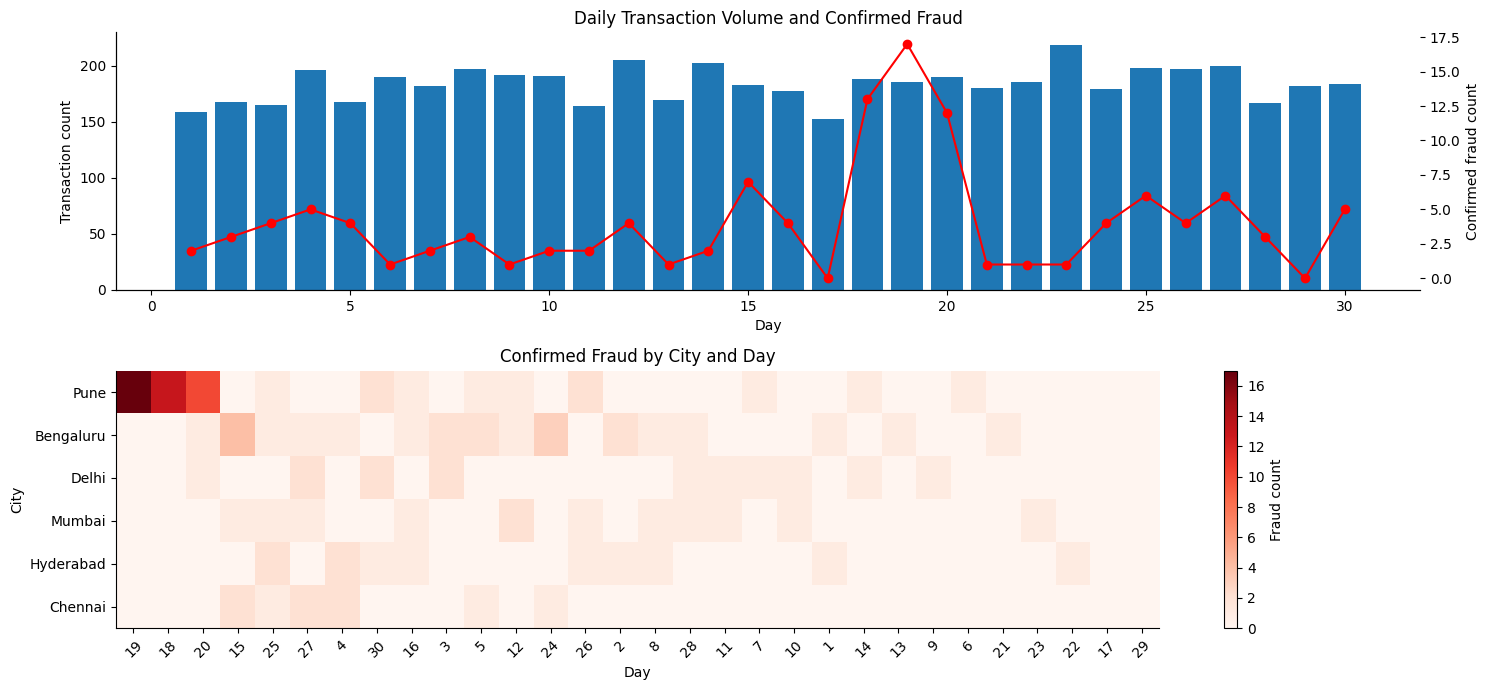

Top city-day cells by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
Chennai    4       2
Bengaluru  3       2
Hyderabad  25      2
Pune       26      2
Chennai    15      2
Name: is_fraud, dtype: int64


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily = tx.groupby("day").agg(transactions=("is_fraud", "size"), fraud=("is_fraud", "sum"))

axes[0].bar(daily.index, daily["transactions"], label="All transactions")
ax2 = axes[0].twinx()
ax2.plot(daily.index, daily["fraud"], color="red", marker="o", label="Confirmed fraud")
axes[0].set_title("Daily Transaction Volume and Confirmed Fraud")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Transaction count")
ax2.set_ylabel("Confirmed fraud count")

# TODO 2
heat = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)

heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
heat = heat[heat.sum(axis=0).sort_values(ascending=False).index]

im = axes[1].imshow(heat, aspect="auto", cmap="Reds")
axes[1].set_title("Confirmed Fraud by City and Day")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("City")
axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns, rotation=45)
axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)
fig.colorbar(im, ax=axes[1], label="Fraud count")

plt.tight_layout(); plt.show()

# TODO 3
top_cells = (tx.groupby(["city", "day"])["is_fraud"].sum().sort_values(ascending=False).head(10))
print("Top city-day cells by confirmed fraud:")
print(top_cells)


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_ The overview shows how fraud varies across days and cities, which an alert list sorted by detector score would not reveal. A heatmap makes clusters of high fraud activity easier to identify, while the daily chart shows changes in overall activity over time. Reordering the matrix by row and column totals helps the strongest patterns stand out. This demonstrates the visual analytics concept of overview first and the use of reordered matrices to reveal patterns.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

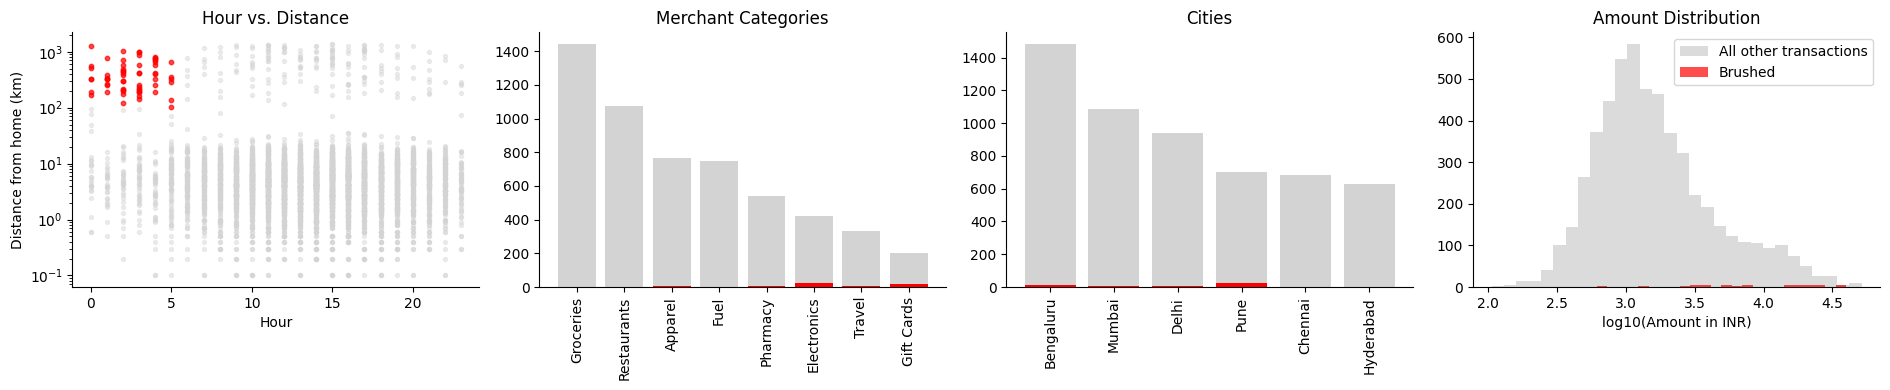

Brushed transactions: 61
Fraud rate in brush: 86.89%
Overall fraud rate: 2.17%
Share of all fraud captured: 44.17%


In [3]:
# TODO 1
brush = (tx["night"]) & (tx["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
axes[0].scatter(
    tx.loc[~brush, "hour"], tx.loc[~brush, "distance_from_home_km"],
    color="lightgrey", alpha=0.4, s=8)
axes[0].scatter(
    tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"],
    color="red", alpha=0.7, s=10)
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from home (km)")
axes[0].set_title("Hour vs. Distance")

categories = tx["merchant_category"].value_counts().index
axes[1].bar(categories, tx["merchant_category"].value_counts().reindex(categories), color="lightgrey")
axes[1].bar(
    tx.loc[brush, "merchant_category"].value_counts().index,
    tx.loc[brush, "merchant_category"].value_counts().values,
    color="red")
axes[1].tick_params(axis="x", rotation=90)
axes[1].set_title("Merchant Categories")

cities = tx["city"].value_counts().index
axes[2].bar(cities, tx["city"].value_counts().reindex(cities), color="lightgrey")
axes[2].bar(
    tx.loc[brush, "city"].value_counts().index,
    tx.loc[brush, "city"].value_counts().values,
    color="red")
axes[2].tick_params(axis="x", rotation=90)
axes[2].set_title("Cities")

axes[3].hist(np.log10(tx.loc[~brush, "amount_inr"].clip(lower=1)), bins=30, color="lightgrey", alpha=0.8, label="All other transactions")
axes[3].hist(np.log10(tx.loc[brush, "amount_inr"].clip(lower=1)), bins=30, color="red", alpha=0.7, label="Brushed")
axes[3].set_xlabel("log10(Amount in INR)")
axes[3].set_title("Amount Distribution")
axes[3].legend()

plt.tight_layout(); plt.show()

# TODO 3
n_brushed = int(brush.sum())
fraud_brushed = int(tx.loc[brush, "is_fraud"].sum())
fraud_total = int(tx["is_fraud"].sum())

rate_brushed = fraud_brushed / n_brushed if n_brushed else 0
rate_overall = tx["is_fraud"].mean()
capture_share = fraud_brushed / fraud_total if fraud_total else 0

print(f"Brushed transactions: {n_brushed:,}")
print(f"Fraud rate in brush: {rate_brushed:.2%}")
print(f"Overall fraud rate: {rate_overall:.2%}")
print(f"Share of all fraud captured: {capture_share:.2%}")


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_ A high fraud rate within the brush does not necessarily mean that the rule captures most fraudulent transactions. The share of all fraud captured tells investigators how much fraud would be missed if they relied on this rule alone. The city-count view can reveal suspicious activity in other locations, while the merchant-category view can show fraud patterns outside the selected group. Therefore, the rule should be used as one investigation signal rather than as the only fraud-detection method.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
times = []
for _ in range(5):
    start = time.perf_counter()
    result = big.loc[(big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)]
    times.append(time.perf_counter() - start)

best_s = min(times)

# TODO 2
per_item_us = best_s * 1_000_000 / len(big)
max_rows = 0.1 * 1_000_000 / per_item_us

# TODO 3
t_50m = per_item_us * 50_000_000 / 1_000_000
skip_pct = max(0, (1 - max_rows / 50_000_000) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 18.4 ms -> 0.0183 us/row -> max 5,460,291 rows in 0.1 s
50M rows -> 0.92 s; must skip 89.1% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_ Besides indexing, sampling or pre-aggregation can reduce the amount of data processed during an interactive query. Sampling can make the slider respond faster, but the analyst may lose rare fraud cases and small clusters that are important for investigations. Pre-aggregation preserves broad trends but can hide individual transactions. The choice depends on whether the analyst needs an overview or must inspect individual suspicious transactions.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

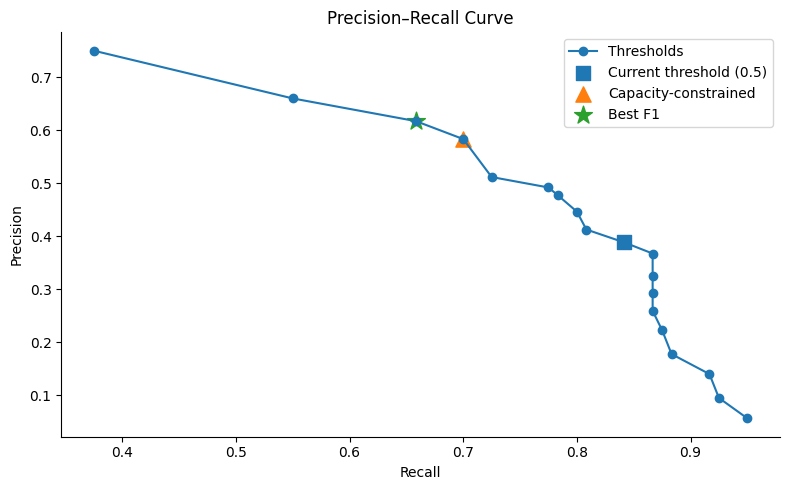

Recommendation: use threshold 0.80 for the capacity limit of 150 alerts (alerts=144.0, precision=58.33%, recall=70.00%). The best-F1 threshold is 0.85.


In [5]:
rows = []
# TODO 1
for threshold in np.arange(0.05, 1.00, 0.05):
    pred = tx["detector_score"] >= threshold
    actual = tx["is_fraud"].astype(bool)

    tp = int((pred & actual).sum())
    fp = int((pred & ~actual).sum())
    fn = int((~pred & actual).sum())
    alerts = int(pred.sum())

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (2 * precision * recall / (precision + recall) if precision + recall else 0)

    rows.append({
        "threshold": round(threshold, 2),
        "alerts": alerts,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "F1": f1
    })

pr = pd.DataFrame(rows)

# TODO 2
eligible = pr[pr["alerts"] <= 150]
capacity_choice = (
    eligible.sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]
    if not eligible.empty else None
)
best_f1 = pr.loc[pr["F1"].idxmax()]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pr["recall"], pr["precision"], marker="o", label="Thresholds")
ax.scatter(
    [pr.loc[pr["threshold"] == 0.5, "recall"].iloc[0]],
    [pr.loc[pr["threshold"] == 0.5, "precision"].iloc[0]],
    marker="s", s=100, label="Current threshold (0.5)"
)
if capacity_choice is not None:
    ax.scatter(capacity_choice["recall"], capacity_choice["precision"],
               marker="^", s=120, label="Capacity-constrained")
ax.scatter(best_f1["recall"], best_f1["precision"],
           marker="*", s=180, label="Best F1")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Curve")
ax.legend()

plt.tight_layout(); plt.show()

# TODO 4
if capacity_choice is not None:
    print(
        f"Recommendation: use threshold {capacity_choice['threshold']:.2f} "
        f"for the capacity limit of 150 alerts "
        f"(alerts={capacity_choice['alerts']}, "
        f"precision={capacity_choice['precision']:.2%}, "
        f"recall={capacity_choice['recall']:.2%}). "
        f"The best-F1 threshold is {best_f1['threshold']:.2f}."
    )
else:
    print("No tested threshold produces 150 or fewer alerts. Review the capacity constraint.")


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_ The Head of Fraud Ops should make the final threshold decision with support from the model's evaluation metrics. The best-F1 threshold balances precision and recall, but it may produce more alerts than the investigation team can handle. A capacity-constrained threshold may reduce workload but miss more fraudulent transactions. Visual analytics keeps a human in the loop because operational capacity, financial risk, and the consequences of missed fraud cannot be decided by a single metric alone.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [7]:
# TODO 1
flagged = tx[tx["detector_score"] >= 0.3].copy()

fig = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    hover_data=[
        "txn_id", "customer_id", "city", "merchant_category",
        "distance_from_home_km", "detector_score"
    ],
    title="Flagged Transactions: Score ≥ 0.3"
)
fig.update_layout(dragmode="select")
fig.show()


# TODO 2
sun = (
    tx.groupby(["city", "merchant_category"], as_index=False)
    .agg(
        transactions=("is_fraud", "size"),
        fraud_count=("is_fraud", "sum")
    )
)
sun["fraud_rate"] = sun["fraud_count"] / sun["transactions"]

fig_sun = px.sunburst(
    sun,
    path=["city", "merchant_category"],
    values="transactions",
    color="fraud_rate",
    color_continuous_scale="Reds",
    title="Transactions by City and Merchant Category"
)
fig_sun.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_ Tooltips are useful for inspecting an individual transaction, but examining hundreds of cases one by one would be slow and frustrating. Investigators would struggle to notice clusters, repeated patterns, and differences between cities or merchant categories. The overview heatmap and linked views from earlier tasks provide a better summary of the overall pattern. The interactive scatterplot can then be used for details-on-demand when an investigator selects a suspicious group or transaction.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: fraud is unusually concentrated in Pune during days [np.int64(18), np.int64(19), np.int64(20)].
Fraud rate inside window: 37.38%
Fraud rate outside window: 1.48%
Chi-square p-value: 1.06482e-136
Window: 107 transactions, fraud rate 37.38%
Same city, other days: 593 transactions, fraud rate 1.85%
Other cities, same days: 457 transactions, fraud rate 0.44%
Rest: 4,363 transactions, fraud rate 1.54%


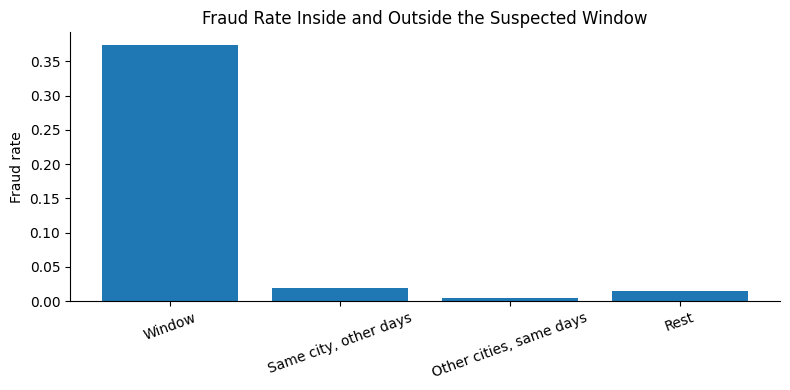

Verdict: The concentration is statistically significant, but this alone does not prove a coordinated fraud ring.


In [8]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
top_city = tx.groupby("city")["is_fraud"].sum().idxmax()
city_days = (
    tx.loc[tx["city"] == top_city]
    .groupby("day")["is_fraud"]
    .sum()
    .sort_values(ascending=False)
)
top_day = city_days.index[0]
day_values = sorted(tx["day"].unique())
day_position = day_values.index(top_day)
window_days = day_values[max(0, day_position - 1):min(len(day_values), day_position + 2)]

in_window = (tx["city"] == top_city) & (tx["day"].isin(window_days))

print(f"Hypothesis: fraud is unusually concentrated in {top_city} during days {window_days}.")

# TODO 2
contingency = pd.crosstab(in_window, tx["is_fraud"])
chi2, p_value, dof, expected = chi2_contingency(contingency)

fraud_rate_window = tx.loc[in_window, "is_fraud"].mean()
fraud_rate_outside = tx.loc[~in_window, "is_fraud"].mean()

print(f"Fraud rate inside window: {fraud_rate_window:.2%}")
print(f"Fraud rate outside window: {fraud_rate_outside:.2%}")
print(f"Chi-square p-value: {p_value:.6g}")

# TODO 3
same_city_other_days = (tx["city"] == top_city) & (~tx["day"].isin(window_days))
other_cities_same_days = (tx["city"] != top_city) & (tx["day"].isin(window_days))
rest = (tx["city"] != top_city) & (~tx["day"].isin(window_days))

groups = {
    "Window": in_window,
    "Same city, other days": same_city_other_days,
    "Other cities, same days": other_cities_same_days,
    "Rest": rest
}

group_rates = {}
for name, mask in groups.items():
    group_rates[name] = tx.loc[mask, "is_fraud"].mean() if mask.any() else 0
    print(f"{name}: {mask.sum():,} transactions, fraud rate {group_rates[name]:.2%}")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(group_rates.keys(), group_rates.values())
ax.set_ylabel("Fraud rate")
ax.set_title("Fraud Rate Inside and Outside the Suspected Window")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout(); plt.show()

# TODO 5
if p_value < 0.05 and fraud_rate_window > fraud_rate_outside:
    print("Verdict: The concentration is statistically significant, but this alone does not prove a coordinated fraud ring.")
else:
    print("Verdict: The evidence is insufficient to establish an unusual fraud concentration or a coordinated fraud ring.")


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_ The counter-example search for the same city on other days could weaken the hypothesis if fraud remained equally high outside the suspected window, suggesting that the city has a consistently higher fraud rate rather than a temporary fraud ring. Similarly, high fraud across other cities during the same days could point to a broader event or system-wide issue. These comparisons help distinguish a local, time-specific pattern from alternative explanations. Even a statistically significant concentration is not sufficient on its own to prove coordination between fraudsters.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_ Last month, PayKart recorded 5,520 transactions and 120 confirmed fraud cases, with a significant concentration in Pune during days 18–20, where 40 of 107 transactions were fraudulent (37.38%). I recommend setting the detector threshold to 0.80, which generates 144 alerts within the team's monthly capacity of 150, achieving 58.33% precision and 70.00% recall; the Head of Fraud Ops should approve the final choice after considering the trade-off between workload and missed fraud. The first interactive view I would build is a linked dashboard with cross-view brushing, allowing investigators to identify suspicious patterns across transaction times, distances, cities, and merchant categories before examining individual cases. This follows the lecture concept of linked highlighting and supports the overview-first approach while allowing details-on-demand through interactive tooltips. Finally, I recommend implementing an investigator feedback loop that records confirmed fraud and false-positive labels and uses them to retrain and evaluate the detector, improving its performance for the following month.